# 06 · Simulación de producción, trazabilidad y rollback

Responde las secciones 4 y 5 del PSet 4 con los datos que dejó el flujo de Kestra `produccion_lotes.yml` en Snowflake (`PRODUCCION.*`).

**Patrón online.** Cada método que diseña el analista es una solicitud a la API, así que la simulación reproduce ese tráfico semana a semana: el lote *k* se envía en la semana *k*, una solicitud por método con hasta 50 analitos.

**Construcción de los lotes.** La OBT no tiene fechas, así que el orden de llegada se aproxima con `EXPERIMENTO_ID` de RepoRT, que crece a medida que los laboratorios depositan sus datos. El entrenamiento usa los experimentos 0006–0275 y los 10 lotes son los experimentos posteriores (0276–0437), cortados en bloques de unas 3 500 filas sin partir ningún experimento (`src/splits.py`).

**Qué limita las conclusiones.** El ID ordena depósitos, no inyecciones, así que no son semanas reales. Además, cada lote reúne pocos laboratorios (los lotes 06, 09 y 10 tienen un solo experimento), por lo que la variación entre lotes mezcla deriva con cambio de laboratorio. Por eso los umbrales de alerta se calibran con pseudo-lotes del propio entrenamiento y no con valores de la literatura.

In [1]:
from pathlib import Path
import json
import os
import sys
import time

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
from mlflow.tracking import MlflowClient

load_dotenv(PROJECT_ROOT / ".env")
from src import almacen
from src.experiments import configure_tracking
from src.reentrenar import MODEL_NAME
from src.simulacion import DERIVA_DESDE_LOTE, FLUJO_SUPUESTO_SIN_DATO, HORIZONTE_LOTES, VOLUMEN_RETARDO_EXTRA_ML

API = os.getenv("API_URL_LOCAL", "http://localhost:8000")
AZUL, NARANJA, GRIS, ROJO = "#2a78d6", "#eb6834", "#8a8984", "#d03b3b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8})
pd.set_option("display.width", 160, "display.max_columns", 30)
configure_tracking()
client = MlflowClient()
q = almacen.consultar

## 1. Los lotes

In [2]:
lotes_doc = pd.read_csv("docs/lotes.csv", dtype={"first_experiment": str, "last_experiment": str})
entradas = q("""SELECT LOTE, MIN(SEMANA_PREDICCION) AS SEMANA_PREDICCION, COUNT(*) AS FILAS,
                    COUNT(DISTINCT EXPERIMENTO_ID) AS EXPERIMENTOS, COUNT(DISTINCT INCHIKEY) AS COMPUESTOS,
                    MIN(EXPERIMENTO_ID) AS PRIMER_EXP, MAX(EXPERIMENTO_ID) AS ULTIMO_EXP
             FROM LOTES_ENTRADAS GROUP BY LOTE ORDER BY LOTE""")
medidas = q("SELECT LOTE, MIN(SEMANA_LLEGADA_TARGET) AS SEMANA_LLEGADA_TARGET, BOOLOR_AGG(DERIVA_INDUCIDA) AS DERIVA FROM LAB_MEDICIONES GROUP BY LOTE")
lotes = entradas.merge(medidas, on="lote").sort_values("lote")
display(lotes_doc.head(1))
display(lotes)
assert len(lotes) >= 8, "El PSet exige al menos 8 lotes"
print(f"{len(lotes)} lotes, {lotes.filas.sum():,} filas; con deriva inducida: {lotes.loc[lotes.deriva, 'lote'].tolist()}")

,segment,experiments,rows,first_experiment,last_experiment
0,entrenamiento,123,103200,0006,0275


,lote,semana_prediccion,filas,experimentos,compuestos,primer_exp,ultimo_exp,semana_llegada_target,deriva
0,1,2026-01-05,3536,26,684,0276,0317,2026-01-12,False
1,2,2026-01-12,3537,11,698,0318,0344,2026-01-19,False
2,3,2026-01-19,3524,10,690,0345,0354,2026-01-26,False
3,4,2026-01-26,4718,10,2835,0355,0383,2026-02-02,False
4,5,2026-02-02,3434,7,3020,0384,0390,2026-02-09,False
5,6,2026-02-09,6509,1,6509,0391,0391,2026-02-16,True
6,7,2026-02-16,3551,14,1567,0392,0414,2026-02-23,True
7,8,2026-02-23,2253,15,1825,0415,0433,2026-03-02,True
8,9,2026-03-02,1324,1,1324,0436,0436,2026-03-09,True
9,10,2026-03-09,1953,1,1953,0437,0437,2026-03-16,True


10 lotes, 34,339 filas; con deriva inducida: [6, 7, 8, 9, 10]


## 2. El horizonte se respeta

El tiempo de retención real de un método se conoce cuando el analista lo inyecta, una semana después de pedir la predicción (`HORIZONTE_LOTES = 1`). En Kestra, la semana *k* predice el lote *k* y publica en `TARGETS` las mediciones del lote *k-1*, que hasta entonces estaban ocultas en `LAB_MEDICIONES`. La semana 11 solo recibe las del lote 10. Se verifica con los datos guardados.

In [3]:
horizonte = q("""SELECT t.LOTE, MIN(t.LLEGO_EN_LOTE) AS LLEGO_EN_SEMANA, MIN(t.CARGADO_EN) AS TARGET_CARGADO,
                       MAX(p.TS) AS ULTIMA_PREDICCION
                FROM TARGETS t JOIN PREDICCIONES p ON p.LOTE = t.LOTE AND p.HECHO_ID = t.HECHO_ID
                GROUP BY t.LOTE ORDER BY t.LOTE""")
horizonte["semanas_despues"] = horizonte["llego_en_semana"] - horizonte["lote"]
horizonte["target_despues_de_predecir"] = pd.to_datetime(horizonte["target_cargado"], utc=True) > pd.to_datetime(horizonte["ultima_prediccion"], utc=True)
display(horizonte)
assert (horizonte["semanas_despues"] == HORIZONTE_LOTES).all()
assert horizonte["target_despues_de_predecir"].all()
print("Cada target llegó exactamente", HORIZONTE_LOTES, "semana después y después de sus predicciones.")

,lote,llego_en_semana,target_cargado,ultima_prediccion,semanas_despues,target_despues_de_predecir
0,1,2,2026-11-22 19:19:58.235416-08:00,2026-11-22 19:18:53.567148-08:00,1,True
1,2,3,2026-11-22 19:21:05.095847-08:00,2026-11-22 19:19:40.239590-08:00,1,True
2,3,4,2026-11-22 19:22:13.024803-08:00,2026-11-22 19:20:49.024225-08:00,1,True
3,4,5,2026-11-22 19:23:20.402470-08:00,2026-11-22 19:21:56.806333-08:00,1,True
4,5,6,2026-11-22 19:24:35.622410-08:00,2026-11-22 19:23:04.297595-08:00,1,True
5,6,7,2026-11-22 19:25:45.995370-08:00,2026-11-22 19:24:19.190956-08:00,1,True
6,7,8,2026-11-22 19:26:56.511649-08:00,2026-11-22 19:25:30.833922-08:00,1,True
7,8,9,2026-11-22 19:55:30.934142-08:00,2026-11-22 19:26:43.057181-08:00,1,True
8,9,10,2026-11-22 19:56:37.310665-08:00,2026-11-22 19:55:15.988118-08:00,1,True
9,10,11,2026-11-23 16:34:25.995982-08:00,2026-11-22 19:56:21.545691-08:00,1,True


Cada target llegó exactamente 1 semana después y después de sus predicciones.


## 3. Qué se alteró en los lotes con deriva inducida

**Escenario.** Desde el lote 06, el laboratorio transfiere sus métodos de un UHPLC (volumen de retardo de unos 0,1 mL) a un HPLC convencional (unos 1,1 mL). El volumen de retardo es el volumen entre el mezclador y la columna. Con 1,0 mL más, el gradiente llega a la columna 1,0/F minutos más tarde, así que **cada tiempo de retención medido se retrasa 1,0/F min**, donde F es el flujo del método en mL/min.

- **Lo que cambia:** solo el target (`LAB_MEDICIONES.TIEMPO_RETENCION`). El valor original se guarda en `TIEMPO_RETENCION_ORIGINAL`.
- **Lo que no cambia:** las entradas que ve el modelo (estructura, columna, fase móvil, flujo, gradiente). Es **deriva conceptual**: la relación entre entradas y target cambió sin que las entradas lo revelen.
- **Lotes 09 y 10:** RepoRT no reporta flujo, así que se asume F = 0,4 mL/min (la mediana de los lotes con flujo).
- **Por qué 1,0 mL y no 0,5 mL:** con 0,5 mL el sesgo del lote 06 (-1,05 min) quedaba dentro de la variación natural entre métodos (umbral calibrado de 1,81 min). No se distinguía de la degradación natural del lote 08.

,retraso_medio_min,retraso_min,retraso_max
lote,,,
1,0.000,0.000,0.000
2,0.000,0.000,0.000
3,0.000,0.000,0.000
4,0.000,0.000,0.000
5,0.000,0.000,0.000
6,1.667,1.667,1.667
7,3.228,2.000,25.000
8,3.565,2.000,6.667
9,2.500,2.500,2.500


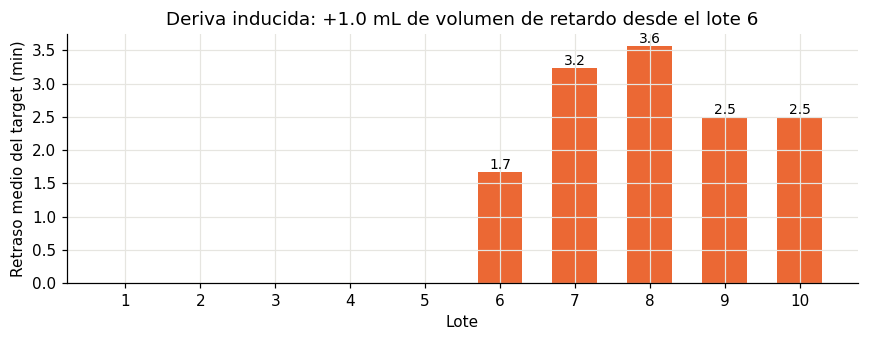

In [4]:
deriva = q("SELECT LOTE, TIEMPO_RETENCION - TIEMPO_RETENCION_ORIGINAL AS RETRASO FROM LAB_MEDICIONES")
resumen = deriva.groupby("lote")["retraso"].agg(["mean", "min", "max"]).round(3)
resumen.columns = ["retraso_medio_min", "retraso_min", "retraso_max"]
display(resumen)
assert (resumen.loc[resumen.index < DERIVA_DESDE_LOTE].abs().max().max() == 0), "Los lotes sin alterar no cambian"

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(resumen.index, resumen["retraso_medio_min"], color=[GRIS if l < DERIVA_DESDE_LOTE else NARANJA for l in resumen.index], width=0.6)
for l, v in resumen["retraso_medio_min"].items():
    if v > 0:
        ax.text(l, v + 0.05, f"{v:.1f}", ha="center", fontsize=9)
ax.set(xlabel="Lote", ylabel="Retraso medio del target (min)", xticks=resumen.index,
       title=f"Deriva inducida: +{VOLUMEN_RETARDO_EXTRA_ML} mL de volumen de retardo desde el lote {DERIVA_DESDE_LOTE}")
plt.tight_layout(); plt.show()

## 4. El flujo `produccion_lotes` en Kestra

Ejecuciones del namespace `qsrr.proyecto`: `produccion_lotes` llama a `monitoreo` cada semana y `monitoreo` llama a `reentrenamiento` cuando corresponde.

In [5]:
auth = (os.getenv("KESTRA_USER"), os.getenv("KESTRA_PASSWORD"))
try:
    r = requests.get("http://localhost:8080/api/v1/main/executions/search", auth=auth, timeout=10,
                     params={"namespace": "qsrr.proyecto", "size": 100, "sort": "state.startDate:asc"})
    ejec = pd.DataFrame([{"flujo": e["flowId"], "semana": (e.get("inputs") or {}).get("semana"),
                          "estado": e["state"]["current"], "inicio": e["state"]["startDate"][:19],
                          "id": e["id"]} for e in r.json()["results"] if e["flowId"] != "t_loop"])
    corrida = ejec[ejec.flujo == "produccion_lotes"].iloc[-1]
    display(ejec[ejec.inicio >= corrida.inicio].reset_index(drop=True))
except requests.RequestException as exc:
    print("Kestra no disponible:", exc)

,flujo,semana,estado,inicio,id
0,produccion_lotes,NaN,SUCCESS,2026-11-23T03:17:58,3aTAQL0NVxgSPBR3r0cFDx
1,monitoreo,1.0,SUCCESS,2026-11-23T03:19:05,5I8DTO7wEDVA14Nen1lbRq
2,monitoreo,2.0,SUCCESS,2026-11-23T03:20:03,5MGOnzKwbAhHogiFXUiSug
3,monitoreo,3.0,SUCCESS,2026-11-23T03:21:10,71AfGsPonESLKrvziONXCc
4,monitoreo,4.0,SUCCESS,2026-11-23T03:22:18,3lkB3kt6H5p7uf61sIrszE
5,monitoreo,5.0,SUCCESS,2026-11-23T03:23:27,2vnT8whz7xJz2cmxM6gHE2
6,monitoreo,6.0,SUCCESS,2026-11-23T03:24:42,7jGZpUpq74c3Vuazfkt7fj
7,monitoreo,7.0,SUCCESS,2026-11-23T03:25:52,ruRzYocz8h6FRLsG0Mwhi
8,monitoreo,8.0,SUCCESS,2026-11-23T03:27:01,RxqtCzeUQX7CL49FjM7PC
9,reentrenamiento,8.0,SUCCESS,2026-11-23T03:27:39,1Cccteyih5CajW8NsdEgKL


## 5. Predicciones registradas y trazabilidad

Cada fila de `PREDICCIONES` guarda id, timestamp, entradas, salida, decisión, versión, alias, run_id y latencia. `SOLICITUDES` guarda una fila por llamada a la API, con su status HTTP.

In [6]:
pred = q("""SELECT LOTE, COUNT(*) AS PREDICCIONES, COUNT(DISTINCT ID_SOLICITUD) AS SOLICITUDES_OK,
                   LISTAGG(DISTINCT VERSION_MODELO, ',') AS VERSIONES, LISTAGG(DISTINCT LEFT(RUN_ID, 8), ',') AS RUN_IDS,
                   AVG(RESPALDO_USADO::INT) AS TASA_RESPALDO, AVG(FUERA_DE_DOMINIO::INT) AS TASA_FUERA_DOMINIO,
                   COUNT_IF(ID_PREDICCION IS NULL OR VERSION_MODELO IS NULL) AS SIN_TRAZA
            FROM PREDICCIONES GROUP BY LOTE ORDER BY LOTE""")
sol = q("SELECT LOTE, COUNT(*) AS SOLICITUDES, COUNT_IF(STATUS <> 200) AS RECHAZADAS FROM SOLICITUDES GROUP BY LOTE")
display(pred.merge(sol, on="lote").round(3))
assert pred["sin_traza"].sum() == 0, "Toda predicción debe indicar su versión"
print("Todas las predicciones indican la versión del modelo que las produjo.")

,lote,predicciones,solicitudes_ok,versiones,run_ids,tasa_respaldo,tasa_fuera_dominio,sin_traza,solicitudes,rechazadas
0,1,3096,71,2,ac566f02,0.000000,0.000000,0,83,12
1,2,3537,75,2,ac566f02,0.000000,0.000000,0,75,0
2,3,3524,75,2,ac566f02,0.000000,0.000000,0,75,0
3,4,4718,101,2,ac566f02,0.000000,0.002755,0,101,0
4,5,3434,71,2,ac566f02,0.000000,0.000000,0,71,0
5,6,6509,131,2,ac566f02,0.000000,0.000000,0,131,0
6,7,3551,76,2,ac566f02,0.000000,0.013799,0,76,0
7,8,2253,52,2,ac566f02,0.000000,0.106081,0,52,0
8,9,1324,27,2,ac566f02,0.000000,0.000000,0,27,0
9,10,1953,40,2,ac566f02,0.000000,1.000000,0,40,0


Todas las predicciones indican la versión del modelo que las produjo.


**Cadena completa de una predicción** (§10.6): predicción → versión y run_id → snapshot de la OBT → tablas Gold.

In [7]:
una = q("SELECT * FROM PREDICCIONES WHERE LOTE = 6 ORDER BY ID_PREDICCION LIMIT 1").iloc[0]
run = client.get_run(una["run_id"])
mv = client.get_model_version(MODEL_NAME, str(int(una["version_modelo"])))
traza = {
    "id_prediccion": una["id_prediccion"], "ts": str(una["ts"]), "lote": int(una["lote"]),
    "smiles": una["smiles"], "prediccion_min": round(float(una["prediccion_min"]), 3), "decision": una["decision"],
    "modelo": f"{MODEL_NAME} v{mv.version}", "run_id": run.info.run_id,
    "fase_corrida": run.data.tags.get("fase"), "obt_snapshot": run.data.tags.get("obt_snapshot_dates"),
    "obt_sha256": run.data.tags.get("data_sha256", "")[:16] + "…", "commit_fuente": run.data.tags.get("obt_source_commits"),
    "tablas_gold": run.data.tags.get("gold_tables"), "commit_codigo": run.data.tags.get("git_commit", "")[:10],
}
display(pd.Series(traza, name="trazabilidad").to_frame())

,trazabilidad
id_prediccion,00002904-e35f-4ac1-abfa-b839dbf9887a
ts,2026-11-22 19:24:18.336733-08:00
lote,6
smiles,C1C2CC3CC1CC(C2)(C3)C(=O)NC(CCCN=C(N)N)C(=O)NC...
prediccion_min,2.346
decision,revisar_condiciones
modelo,qsrr-predict-modelo v2
run_id,ac566f02d1c746a683554232c7573927
fase_corrida,entrenamiento_descriptores_metodo
obt_snapshot,2026-11-20


## 6. Desempeño por lote cuando llega el target

El RMSE se calcula contra el tiempo medido (con la deriva) y contra el original (sin ella). La diferencia aísla el efecto de la deriva inducida del cambio natural entre laboratorios.

,n,rmse_medido,sesgo_medido,rmse_sin_deriva,sesgo_sin_deriva,alerta
lote,,,,,,
1,3096.0,1.680,0.877,1.680,0.877,False
2,3537.0,1.364,0.957,1.364,0.957,False
3,3524.0,0.738,-0.119,0.738,-0.119,False
4,4718.0,1.964,-0.203,1.964,-0.203,False
5,3434.0,1.434,-0.196,1.434,-0.196,False
6,6509.0,2.175,-1.884,1.108,-0.217,True
7,3551.0,5.340,-3.202,2.658,0.026,True
8,2253.0,5.073,-1.196,5.352,2.369,True
9,1324.0,3.427,-2.773,2.032,-0.273,True


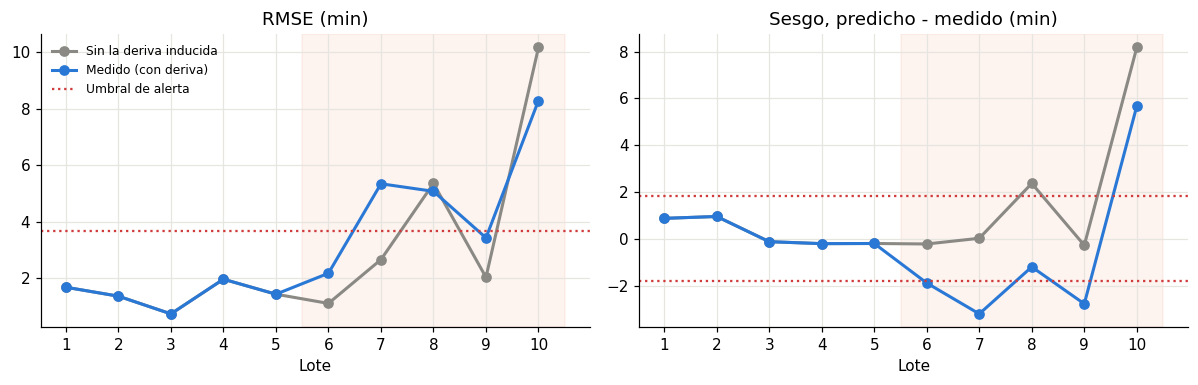

Sombreado: lotes con deriva inducida.


In [8]:
cruce = q("""SELECT p.LOTE, p.EXPERIMENTO_ID, p.PREDICCION_MIN, m.TIEMPO_RETENCION, m.TIEMPO_RETENCION_ORIGINAL
            FROM PREDICCIONES p JOIN TARGETS t ON p.LOTE = t.LOTE AND p.HECHO_ID = t.HECHO_ID
            JOIN LAB_MEDICIONES m ON m.LOTE = t.LOTE AND m.HECHO_ID = t.HECHO_ID""")
def resumen_lote(g):
    e, e0 = g.prediccion_min - g.tiempo_retencion, g.prediccion_min - g.tiempo_retencion_original
    return pd.Series({"n": len(g), "rmse_medido": np.sqrt((e ** 2).mean()), "sesgo_medido": e.mean(),
                      "rmse_sin_deriva": np.sqrt((e0 ** 2).mean()), "sesgo_sin_deriva": e0.mean()})
desempeno = cruce.groupby("lote").apply(resumen_lote, include_groups=False).round(3)
ref = json.loads(Path("monitoreo/referencia.json").read_text(encoding="utf-8"))
umbral_rmse = ref["umbrales"]["rmse_lote"]; umbral_sesgo = ref["umbrales"]["sesgo_abs_lote"]
desempeno["alerta"] = (desempeno.rmse_medido > umbral_rmse) | (desempeno.sesgo_medido.abs() > umbral_sesgo)
display(desempeno)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (col, col0, u, titulo) in zip(axes, [("rmse_medido", "rmse_sin_deriva", umbral_rmse, "RMSE (min)"),
                                             ("sesgo_medido", "sesgo_sin_deriva", umbral_sesgo, "Sesgo, predicho - medido (min)")]):
    ax.plot(desempeno.index, desempeno[col0], color=GRIS, marker="o", lw=2, label="Sin la deriva inducida")
    ax.plot(desempeno.index, desempeno[col], color=AZUL, marker="o", lw=2, label="Medido (con deriva)")
    ax.axhline(u, color=ROJO, ls=":", lw=1.5, label="Umbral de alerta")
    if col == "sesgo_medido":
        ax.axhline(-u, color=ROJO, ls=":", lw=1.5)
    ax.axvspan(DERIVA_DESDE_LOTE - 0.5, desempeno.index.max() + 0.5, color=NARANJA, alpha=0.08)
    ax.set(xlabel="Lote", title=titulo, xticks=desempeno.index)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print("Sombreado: lotes con deriva inducida.")

**Lectura.** La deriva inducida explica las alertas de los lotes 06, 07 y 09. Sin ella, esos lotes quedan dentro de los dos umbrales; con ella, el modelo predice consistentemente antes de lo que eluye el compuesto (sesgo negativo). En el lote 06 la alerta de sesgo aparece en el primer lote alterado, aunque por poco (1,88 frente a 1,81 min). En el lote 07 el RMSE se duplica (2,66 → 5,34 min), y su retraso máximo es de 25 min porque un método usa 0,04 mL/min.

Los lotes 08 y 10 fallan **incluso sin la deriva inducida**, por degradación natural: el 10,6 % del lote 08 y todo el lote 10 quedan fuera del dominio de entrenamiento (columna de 1 mm y gradiente de 100 min), y la guardia de dominio de la API ya los marcaba. En esos dos lotes el modelo sobreestimaba el tiempo, así que el retraso inducido reduce su error. Es una advertencia para la sección 7: la caída del lote 08 no se puede atribuir solo a la deriva inducida.

## 7. Versionado: regla de promoción y ciclos de reentrenamiento

**Regla de promoción** (`src/reentrenar.py::comparar`). El challenger se promueve si, en el mismo lote etiquetado más reciente (que ninguno de los dos vio), su RMSE es menor que el del champion por **más de una desviación estándar de la CV del champion**, y si su métrica de negocio no es peor. Aun así, la promoción espera la aprobación de una persona en la pausa de Kestra.

In [9]:
reent = q("SELECT * FROM REENTRENAMIENTOS ORDER BY LOTE")
cols = ["lote", "motivo", "ventana", "version_champion", "version_challenger", "lote_evaluacion", "rmse_champion",
        "rmse_challenger", "cv_std_champion", "negocio_champion", "negocio_challenger", "regla_promueve",
        "decision_humana", "motivo_decision", "version_champion_final"]
reent = reent[cols].assign(mejora=lambda d: (d.rmse_champion - d.rmse_challenger).round(3))
display(reent.T)

,0,1
lote,8,10
motivo,desempeño: alerta de RMSE o sesgo en 2 lotes c...,desempeño: alerta de RMSE o sesgo en 2 lotes c...
ventana,"histórico 0006-0275 (peso 1) + lotes [1, 2, 3,...","histórico 0006-0275 (peso 1) + lotes [1, 2, 3,..."
version_champion,2,2
version_challenger,4,5
lote_evaluacion,7,9
rmse_champion,5.339927,3.426741
rmse_challenger,5.310008,2.861893
cv_std_champion,0.034774,0.034774
negocio_champion,0.0,0.0


## 8. Rollback sin reconstruir la imagen

El rollback consiste en mover el alias `champion` en el Model Registry a la versión anterior. La API vuelve a revisar el alias cada `MODELO_TTL_S = 30` s y carga la versión nueva sin reiniciar el contenedor. Aquí se mueve el alias al champion anterior, se espera el TTL, se consulta `/modelo` y se hace una predicción, y después se restaura.

In [10]:
SOLICITUD = {
    "tipo_columna": "Waters ACQUITY UPLC BEH C18",
    "fase_movil": "A[H2O=100; MeOH=0; ACN=0] B[H2O=0; MeOH=0; ACN=100]",
    "flujo_ml_min": 0.4, "t0_min": 0.5, "columna_longitud_mm": 100, "columna_diametro_mm": 2.1,
    "columna_particula_um": 1.7, "ph_a": 2.7, "ph_b": 2.7,
    "gradiente": [{"t_min": 0, "a_pct": 95, "b_pct": 5}, {"t_min": 10, "a_pct": 5, "b_pct": 95},
                  {"t_min": 12, "a_pct": 5, "b_pct": 95}],
    "compuestos": [{"id": "cafeina", "smiles": "Cn1cnc2c1c(=O)n(C)c(=O)n2C"},
                   {"id": "ibuprofeno", "smiles": "CC(C)Cc1ccc(cc1)C(C)C(=O)O"}],
}
TTL_S = 35

def estado(paso):
    m = requests.get(f"{API}/modelo", timeout=30).json()
    p = requests.post(f"{API}/predecir", json=SOLICITUD, timeout=60).json()
    return {"paso": paso, "hora_utc": pd.Timestamp.utcnow().strftime("%H:%M:%S"), "modelo_version": m["version"],
            "modelo_run_id": m["run_id"][:8], "prediccion_version": p["version_modelo"],
            "cafeina_min": round(p["predicciones"][0]["tiempo_retencion_min"], 3)}

actual = int(client.get_model_version_by_alias(MODEL_NAME, "champion").version)
anterior = int(reent.loc[reent.decision_humana == "aprobado", "version_champion"].iloc[-1])
pasos = [estado(f"antes: champion = v{actual}")]
client.set_registered_model_alias(MODEL_NAME, "champion", str(anterior))
time.sleep(TTL_S)
pasos.append(estado(f"rollback: alias champion -> v{anterior}"))
client.set_registered_model_alias(MODEL_NAME, "champion", str(actual))
time.sleep(TTL_S)
pasos.append(estado(f"restaurado: alias champion -> v{actual}"))
rollback = pd.DataFrame(pasos)
display(rollback)
assert rollback.modelo_version.tolist() == [actual, anterior, actual]
assert (rollback.modelo_version == rollback.prediccion_version).all()
rollback.to_csv("docs/rollback.csv", index=False)
print("El alias se movió dos veces y la API siguió cada cambio sin reconstruir ni reiniciar el contenedor.")

,paso,hora_utc,modelo_version,modelo_run_id,prediccion_version,cafeina_min
0,antes: champion = v5,00:44:19,5,372817b3,5,3.717
1,rollback: alias champion -> v2,00:44:58,2,ac566f02,2,2.892
2,restaurado: alias champion -> v5,00:45:38,5,372817b3,5,3.717


El alias se movió dos veces y la API siguió cada cambio sin reconstruir ni reiniciar el contenedor.
